# 01 Backtest: momentum vs 60/40

Runs the tactical asset-allocation backtest and prints the headline statistics.

- **Strategy:** each month, hold the top 3 of 7 ETFs ranked by 12-month momentum (skipping the latest month); an ETF with negative momentum is replaced by cash.
- **Benchmark:** static 60% SPY / 40% IEF, rebalanced monthly.
- The strategy code lives in `src/backtest.py`, shared by all notebooks in this project.

In [3]:
# Run once if yfinance is not installed yet (then restart the kernel):
# %pip install -q yfinance

In [4]:
import sys
sys.path.insert(0, "..")   # lets the notebook find the src/ folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.backtest import *

FIGURES = "../reports/figures"

## Run the backtest

In [5]:
res = run_comparison()

summarise(res["strategy"], "Momentum strategy (net of costs)", res["turnover"])
summarise(res["bench"], "Benchmark 60/40")

cash_months = (res["weights"].loc[res["first_live"]:].sum(axis=1) == 0).mean()
print(f"\n  Months fully in cash:  {cash_months:7.2%}")

Loaded 262 months of real data (2005-01 to 2026-10)
Period: 2006-03-31 to 2026-10-31 (248 months)

Momentum strategy (net of costs)
--------------------------------
  CAGR                    7.92%
  Volatility             11.99%
  Sharpe                   0.49
  Max drawdown          -19.13%
  Calmar                   0.41
  Positive months        57.26%
  Avg monthly turnover   27.02%

Benchmark 60/40
---------------
  CAGR                    8.16%
  Volatility              9.25%
  Sharpe                   0.67
  Max drawdown          -29.46%
  Calmar                   0.28
  Positive months        66.94%

  Months fully in cash:    2.81%


## Growth and drawdowns

Chart saved to ../reports/figures/growth_drawdown.png


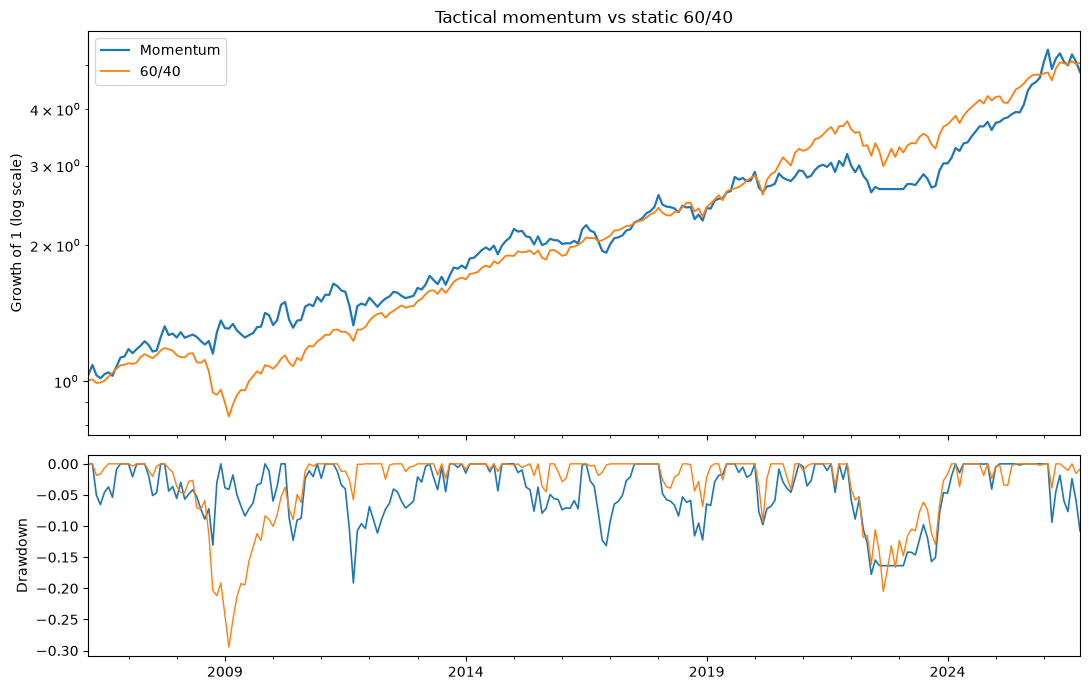

In [6]:
plot_results(res["strategy"], res["bench"], save_path=f"{FIGURES}/growth_drawdown.png")